# Códigos Resolução de Sistemas lineares: Métodos Diretos e Interativos

In [1]:
""" Bibliotecas """
import numpy as np

## Métodos Diretos

### Fatoração LU

In [2]:
A = np.array([[6,3,0,0,0],[3,10,2,0,0],[0,0,3,16,5],[0,0,0,5,10]])

In [2]:
def troca_pivo(A: np.array, linha: int) -> list[np.array, np.array, int]:
    n = len(A) # verifica o tamanho da matriz A
    i_p = linha + np.argmax(np.abs(A[linha:,linha])) # verifica em qual linha da coluna "linha" está o maior pivo
    if np.isclose(A[i_p, linha], 0): # Se o pivo é zero em todas as linhas 
        raise ValueError("Matriz singular")
    p = np.eye(n) # Cria a matriz de permutacao
    p[[linha, i_p]] = p[[i_p, linha]] # troca as linhas da matriz de permutação

    return p@A, p, i_p # retorna "A" com as linhas trocadas, matriz de permutacao, e indice do pivo



In [3]:
def LU(A: np.array) -> list[np.array, np.array, np.array, np.array]:
    Es = [] # vetor das matrizes elementares
    permutacoes = [] # vetor das matrizes de permutacao
    n = len(A) # tamanho de A
    U = A.copy() # U que inicialmente é uma cópia de A
    L = np.eye(n) # L começando sendo a matriz idenditade de dimensão do A
    P = np.eye(n) # P começando sendo a matriz idenditade de dimensão do A
    for i in range(n - 1): # da primeira linha até a penúltima linha
        if np.isclose(U[i, i], 0): # verifica se o pivô é nulo
            try:
                U, p, i_p = troca_pivo(U, i) # tenha achar o pivo não nulo na coluna do pivo nulo
            except ValueError: # se não acharzzzz
                print("Matriz singular") # ...
                break
            L[[i, i_p], :i] = L[[i_p, i],:i] # troca as linhas de L, linha pivo nulo com linha maior pivo
            permutacoes.append(p) # adiciona a matriz de permutacao 
            P = p@P # faz a troca de linha da matriz de permutacao

        E = np.eye(n) # cria a matriz elementar do mesmo tamanho que a matriz A
        E[i+1:,i] = [-U[j,i]/U[i,i] for j in range(i+1,n)] # Faz a operacao na coluna do pivo dos elementos da matriz elementar
        U = E@U # multiplica a matriz elementar por U que inicialmente U = A
        L = L@np.linalg.inv(E) # cria o primeiro L multiplicando L pela inversa de E
        Es.append(E) # adiciona E no vetor das matrizes elementares. 
    return L, U, Es, permutacoes
                        

In [5]:
L, U, Es, permutacoes = LU(A)
print(L)
print(U)
print(L@U)

[[1.  0.  0.  0. ]
 [0.5 1.  0.  0. ]
 [0.  0.  1.  0. ]
 [0.  0.  0.  1. ]]
[[ 6.   3.   0.   0.   0. ]
 [ 0.   8.5  2.   0.   0. ]
 [ 0.   0.   3.  16.   5. ]
 [ 0.   0.   0.   5.  10. ]]
[[ 6.  3.  0.  0.  0.]
 [ 3. 10.  2.  0.  0.]
 [ 0.  0.  3. 16.  5.]
 [ 0.  0.  0.  5. 10.]]


### Decomposição em Valores Singulares (SVD)

In [ ]:
A = np.array([[1,2,0],[2,0,2]])

In [ ]:
def SVD(A: np.array) -> tuple[np.array, np.array, np.array]:
    """
    Entrada: Matriz np.array(A)

    Saída: Uma trupla de matrizes U, E e V transposto
    """
    m, n = A.shape # Pega a dimensão da matriz A
    A_tA = np.transpose(A)@A # Calcula A transposto vezes A
    AA_t = A@np.transpose(A) # Calcula A vezes A transposto
    posto = np.linalg.matrix_rank(A) # Calcula a máximo de linhas ou colunas Linearmente independentes

    Autvalores, V = np.linalg.eigh(A_tA) # Retorna ous autovalores e autovetores da matriz A transposto A

    ord = np.argsort(Autvalores)[::-1] # cria um vetor de indices, em que os maiores números correspondem aos maiores valores do vetor Autovalores
    Autvalores = Autvalores[ord] # Ordena o vetor de autovalores do maior para o menor
    V = V[:,ord] # Ordena as colunas da matriz V para ficar de acordo com a ordem do vetor de autovalores

    sigma = np.array([np.sqrt(i) for i in Autvalores if i > 0]) # Calcula os sigmas do vetor de autovalores positivos
    # sigma = np.sqrt(np.clip(Autvalores, 0, None))
    E_p = np.eye(posto) # Cria a matriz em que a diagonal principal será os sigmas
    for i in range(len(sigma)): # Muda a diagonal principal da matriz E_p para os sigmas 
        E_p[i,i] = sigma[i]

    E = np.zeros((m,n)) # Cria a matriz e de dimensão mXn
    E_plus = np.zeros((n,m)) # Cria a matriz E_plus de dimensão mXn
    E[:posto, :posto] = E_p # A submatriz E_postoXposto da matriz E recebe E_p
    E_plus[:posto,:posto] = np.linalg.inv(E_p) # A submatriz E_{plus}_{postoXposto} da matriz inversa da E recebe E_p


    # AutvetoresAA_t = np.linalg.eigh(AA_t)[1]
    # U = AutvetoresAA_t

    U = np.zeros((m,m)) # Cria a matriz U
    for i in range(posto): 
        U[:,i] = (A@V[:, i])/sigma[i] # Cada coluna da matriz U recebe a linha da operação A@V[:,i], com essa linha sendo dividida por sigma[i]

    return U, E, V, E_plus # Retorna U, E e a transposta da V

In [ ]:
U, E, V_t, E_plus = SVD(A)

In [ ]:
print(U)
print(E)
print(V_t)   
print(E_plus)

In [ ]:
a = U@E@np.transpose(V_t)
print(a)
print(A)

In [ ]:
U, sigma, Vt = np.linalg.svd(A, full_matrices=True)

E = np.zeros(A.shape)
limite = min(A.shape)
E[np.arange(limite), np.arange(limite)] = sigma

print(U @ E @ Vt)

## Métodos interativos

### Jacobi, Gauus-Sidel e SOR

In [8]:
A = np.array([[6,3,0,0,0],[3,10,2,0,0],[0,2,10,3,0],[0,0,3,16,5],[0,0,0,5,10]], dtype=float)
b = np.array([[0],[-3],[18],[-18],[-6]], dtype=float)
m,n = A.shape
D = np.zeros((m,n))
L = np.zeros((m,n))
U = np.zeros((m,n))
for i in range(m):
    for j in range(n):
        if i == j:
            D[i,j] = A[i,j]
        if i > j:
            L[i,j] = A[i,j]
        if i < j:
            U[i,j] = A[i,j]

x_k = np.ones((m,1))

# w para o método SOR
w = 1.058

In [9]:
cont = 0
while True:
    if cont == 0:
        # Critério das linhas
        sigma = np.zeros(m)
        B = np.linalg.inv(D)@(L + U) 
        for i in range(m):
            soma = 0
            for j in range(n):
                soma += np.abs(A[i,j]) - A[i,j]
            sigma[i] = (1/(np.abs(A[i,i]))) * soma

        if any(x>1 for x in sigma):
            print(f"Sigma's:{sigma}")
            break
        else:
            print(f"Sigma's:{sigma}")
            cont+=1
    # Método de Jacobi
    # x_kplu1 = np.linalg.inv(D)@[b - (L+U)@x_k]
    # print(x_k)

    # Método de Gauss-Seidel
    J = L+D
    x_kplu1 = np.linalg.inv(J)@(b - U@x_k)
    print(x_k)
    
    # Método de SOR
    # x_sor = (1-w)*x_k + w*x_kplu1
    # print(x_sor)
    
    # Critério de parada
    if np.max(np.abs(x_kplu1) - x_k) < 1e-2:
        break
    else:
        x_k = x_kplu1
        # x_k = x_sor
    

Sigma's:[0. 0. 0. 0. 0.]
[[1.]
 [1.]
 [1.]
 [1.]
 [1.]]
[[-0.5      ]
 [-0.35     ]
 [ 1.57     ]
 [-1.731875 ]
 [ 0.2659375]]
[[ 0.175     ]
 [-0.6665    ]
 [ 2.4528625 ]
 [-1.66801719]
 [ 0.23400859]]
[[ 0.33325   ]
 [-0.8905475 ]
 [ 2.47851466]
 [-1.66284918]
 [ 0.23142459]]
[[ 0.44527375]
 [-0.92928506]
 [ 2.48471177]
 [-1.66320364]
 [ 0.23160182]]
[[ 0.46464253]
 [-0.93633511]
 [ 2.48622811]
 [-1.66354334]
 [ 0.23177167]]
[[ 0.46816756]
 [-0.93769589]
 [ 2.48660218]
 [-1.66366656]
 [ 0.23183328]]
[[ 0.46884794]
 [-0.93797482]
 [ 2.48669493]
 [-1.6637032 ]
 [ 0.2318516 ]]
[[ 0.46898741]
 [-0.93803521]
 [ 2.486718  ]
 [-1.66371325]
 [ 0.23185663]]
[[ 0.4690176 ]
 [-0.93804888]
 [ 2.48672375]
 [-1.6637159 ]
 [ 0.23185795]]
[[ 0.46902444]
 [-0.93805208]
 [ 2.48672519]
 [-1.66371658]
 [ 0.23185829]]
[[ 0.46902604]
 [-0.93805285]
 [ 2.48672554]
 [-1.66371676]
 [ 0.23185838]]
[[ 0.46902642]
 [-0.93805304]
 [ 2.48672563]
 [-1.6637168 ]
 [ 0.2318584 ]]
[[ 0.46902652]
 [-0.93805308]
 [ 2.48

KeyboardInterrupt: 

### Gradiente Conjugado

In [76]:
A = np.array([
    [4,2,-4],
    [2,10,4],
    [-4,4,9]
], dtype=float)

b = np.array([
    [0],
    [6],
    [5]
], dtype=float)

tol = 0.2e-3
n = len(A)
x0 = np.zeros((n,1))

In [104]:
Fx = 1/2*(np.transpose(x0))@A@x0 -np.transpose(b)@x0
gradFx = A@x0 - b
r = -gradFx
s = (np.transpose(r)@r)/(np.transpose(r)@A@r)
x = x0 - s*gradFx
print(r)

[[-0.]
 [ 6.]
 [ 5.]]


In [113]:
aux = (r.T @ r).item()
print(np.sqrt(r))

[[-0.        ]
 [ 2.44948974]
 [ 2.23606798]]


In [120]:
def GradConjugado(A: np.array, b: np.array, x0: np.array, tol: float, epocas: int) -> np.ndarray:
    n = len(A)
    # Verificando se a matriz A é simétrica e positiva definida
    if np.all(A == np.transpose(A)):
        for i in range(1,n+1):
            det = np.linalg.det(A[:i,:i])
            if det <= 0:
                return("Não é positiva definida")
            else:
                continue
    else:
        return("Matriz não é simétrica")

    x = x0.copy()
    r = b- A@x
    aux = (r.T @ r).item()
    v = r.copy()
    for _ in range(epocas):
        z = A@v
        s = aux/(v.T @ z).item()
        x = x + s*v
        r = r-s*z
        aux1 = (r.T @ r).item()

        if np.sqrt(aux1) < tol:
            return x
        else:
            m = aux1/aux
            aux = aux1
            v = r + m*v

    print(f"Número de épocas ({epocas}) atingido.")
    return x

In [122]:
x_cg = GradConjugado(A, b, x0, tol=0.2e-3, epocas=10)
x_direto = np.linalg.solve(A, b)

print(x_cg)
print(x_direto)
print(np.linalg.norm(A @ x_cg - b))

[[1.00000000e+00]
 [1.44328993e-15]
 [1.00000000e+00]]
[[1.]
 [0.]
 [1.]]
2.062028195525283e-14


# Resolução de Equações Não-Lineares

## Método da Bissecção

In [2]:
import matplotlib.pyplot as plt
import numpy as np

In [15]:
x = np.linspace(-2,2,50)
y = 2*np.sin(x) - x*np.cos(x)-1

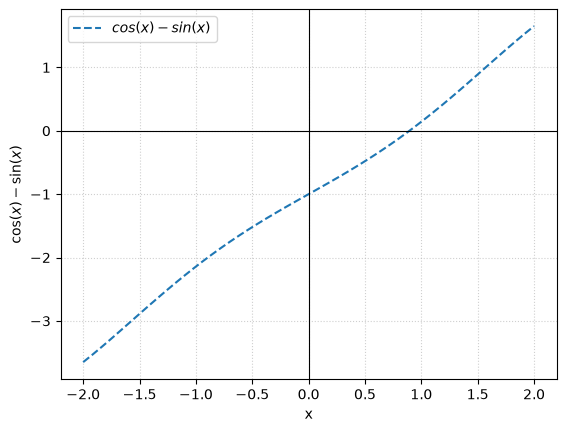

In [16]:
plt.plot(x,y, '--', label =r"$cos(x)-sin(x)$")
plt.axhline(0, color="black", linewidth=0.8)  # eixo x: y = 0
plt.axvline(0, color="black", linewidth=0.8)  # eixo y: x = 0

plt.xlabel("x")
plt.ylabel(r"$\cos(x) - \sin(x)$")
plt.grid(True, linestyle=":", alpha=0.6)

plt.legend()
plt.show()

In [12]:
def f(x):
  return 2*np.sin(x) - x*np.cos(x)-1
def bissec(a0, b0, Ep):
  k = 0
  pontos = []
  while (b0 - a0) > Ep:
    x = (a0 + b0)/2
    if f(x)*f(a0) > 0:
      a0 = x
    else:
      b0 = x
    k += 1
    pontos.append(((a0+b0)/2, f((a0+b0)/2)))
  y = (a0 + b0)/2
  return y, pontos


In [17]:
y, pontos =bissec(0,1, 1e-5)

In [18]:
print(y)

0.8945655822753906


# Interpolação Polinômial

### Forma de Lagrange

In [2]:
## Algoritmo para calcular os coeficientes do polinômio interpodalor de Lagrange
def f(x):
    return 1/x

def coefLagrange(pontos, x):
    n = len(pontos)
    y_s = [f(pontos[i]) for i in range(n)]
    p_n = []
    coef_k = []
    soma = 0
    lista_L_k = []
    for i in range(n):
        L_k = 1
        for k in range(n):
            for p in pontos:
                if pontos[k] != p:
                    L_k*=(x - p)/(pontos[k] - p)
            lista_L_k.append(L_k)
        coef_k.append(y_s[k]*lista_L_k[k])
        soma += coef_k[i]
    return soma

In [3]:
pontos = [2, 1.5, 4]
valor = coefLagrange(pontos=pontos,x= 3)
print(valor)

-0.27


### Diferenças Dvididas

In [ ]:
x = [0,1,2,3]
y = [1,2,0,5]

x_eval = 1.5

n = len(x)
dd = np.zeros((2*n-1,n))
for i in range(len(dd[:,0])):
    if i%2==0:
        j = int(i/2)
        dd[i,0] = y[j]
# print(dd)
for coluna in range(1,n):
  for linha in range(n - coluna):
    linha_dd = 2*linha + coluna
    dd[linha_dd,coluna] = (dd[linha_dd+1,coluna-1] -dd[linha_dd-1,coluna-1])/(x[linha + coluna] - x[linha])
print(dd)




[[ 1.          0.          0.          0.        ]
 [ 0.          1.          0.          0.        ]
 [ 2.          0.         -1.5         0.        ]
 [ 0.         -2.          0.          1.66666667]
 [ 0.          0.          3.5         0.        ]
 [ 0.          5.          0.          0.        ]
 [ 5.          0.          0.          0.        ]]


In [74]:
# caso eu queira uma matriz sem zeros
dd = np.zeros((n,n))
dd[:,0] = y
for coluna in range(1,n):
    for linha in range(n-coluna):
        dd[linha, coluna] = (
            dd[linha + 1, coluna - 1] - dd[linha, coluna - 1]
        ) / (x[linha + coluna] - x[linha])
print(dd)

[[ 1.          1.         -1.5         1.66666667]
 [ 2.         -2.          3.5         0.        ]
 [ 0.          5.          0.          0.        ]
 [ 5.          0.          0.          0.        ]]


### Polinômio Interpolador com Nós de Chebyshev

In [3]:
def ws(raiz, x):
    w = 1
    for i in raiz:
        w *= (x - i)
    
    return w


In [ ]:
a = 0
b = 1
i = np.arange(0,20+1,1)
xi = a + i/len(i)*(b-a)
intervalo = np.arange(0,1,0.1)

[0.         0.04761905 0.0952381  0.14285714 0.19047619 0.23809524
 0.28571429 0.33333333 0.38095238 0.42857143 0.47619048 0.52380952
 0.57142857 0.61904762 0.66666667 0.71428571 0.76190476 0.80952381
 0.85714286 0.9047619  0.95238095]


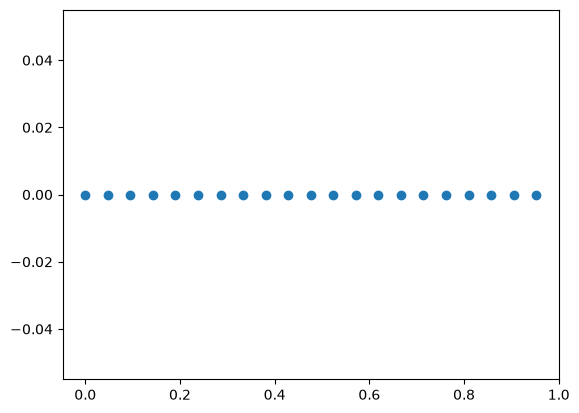

In [26]:
import matplotlib.pyplot as plt
zero = np.zeros(len(xi))
plt.scatter(xi,zero)

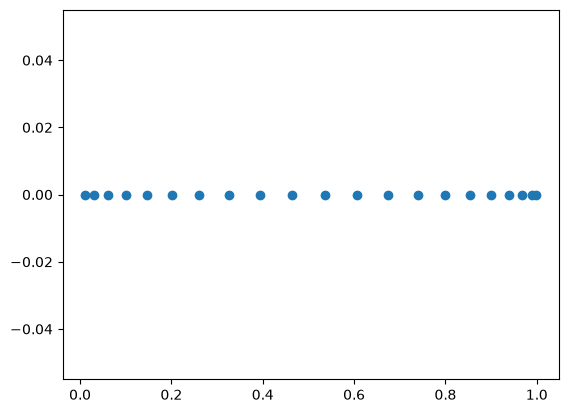

In [31]:
c = 0
d = 1
xic = (a+b)/2 +(b-a)/2*np.cos((2*i+1)/(len(i)+1)*np.pi/2)
zeros2 = np.zeros(len(xic))
plt.scatter(xic, zeros2)

### Splines

In [25]:
"""
Base para Splines Lineares
"""

def funcChapeu(particao):
    l = []
    x = []
    for i in range(1, len(particao)-1):
        xs = np.arange(particao[i-1], particao[i+1], 0.1)
        ls = []

        for p in xs:
            if particao[i-1] <= p < particao[i]:
                li = float((p-particao[i-1])/(particao[i] - particao[i-1]))
                ls.append(li)
            if particao[i] <= p <= particao[i+1]:
                li = float((particao[i+1]-p)/(particao[i+1] - particao[i]))
                ls.append(li)
            else:
                continue
        l.append(ls)
        x.append(xs)
    return l, x
    

In [32]:
p = np.arange(0,5, 1)
particao = p
ls, xs = funcChapeu(particao=particao)

AttributeError: Line2D.set() got an unexpected keyword argument 'legend'

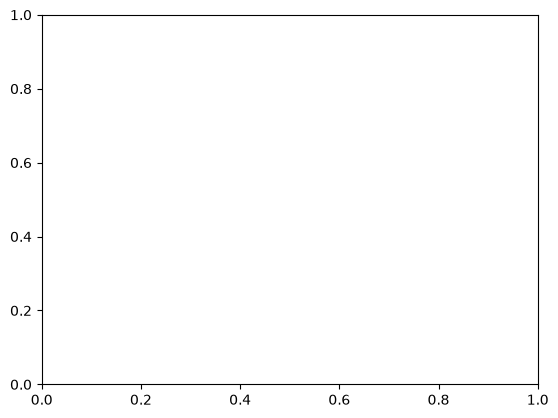

In [ ]:
import matplotlib.pyplot as plt

for par in range(len(ls)):
    plt.plot(xs[par], ls[par])

plt.show()


# Equações Diferenciais.

In [10]:
import numpy as np

h = 0.1
x = np.linspace(0.0, 1.0, 11)
h = x[1] - x[0]

y_esquerda = 0.0
y_direita = np.exp(1)

n_interno = len(x) - 2
A = np.zeros((n_interno, n_interno))
B = np.zeros(n_interno)

for linha, i in enumerate(range(1, len(x) - 1)):
    inferior = 2 + h
    diagonal = 2 * i * h**3 - 4
    superior = 2 - h

    A[linha, linha] = diagonal
    B[linha] = 2 * h**2 * np.exp(x[i]) * (x[i]**2 + 1)

    if linha > 0:
        A[linha, linha - 1] = inferior
    else:
        B[linha] -= inferior * y_esquerda

    if linha < n_interno - 1:
        A[linha, linha + 1] = superior
    else:
        B[linha] -= superior * y_direita

y_interno = np.linalg.solve(A, B)

In [12]:
y = np.concatenate(([y_esquerda], y_interno, [y_direita]))
print(y)

[0.         0.11040087 0.24405639 0.40463826 0.59633353 0.82391233
 1.09280412 1.40918345 1.78006654 2.21341978 2.71828183]
